# 01 - Data Cleaning & Exploratory Data Analysis

**Dataset:** Online Shoppers Purchasing Intention (UCI)
**Target:** `Revenue` (True = purchase made, False = no purchase)

This notebook covers:
1. Loading the raw dataset
2. Initial inspection (shape, types, missing values, duplicates)
3. Cleaning (drop duplicates, fix types)
4. Exploratory Data Analysis (target balance, numeric distributions, categorical vs. target, correlations)
5. Saving the cleaned dataset for the modeling notebook

Run cells top to bottom with **Shift+Enter**, same as Colab.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

project_folder = Path.cwd().parent
raw_path = project_folder / "dataset" / "online_shoppers_intention.csv"
cleaned_path = project_folder / "dataset" / "online_shoppers_intention_cleaned.csv"

df = pd.read_csv(raw_path)
print("Shape:", df.shape)
df.head()

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 1. Initial Inspection

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [3]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,12330.0,NaN,NaN,NaN,2.315166,3.321784,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,12330.0,NaN,NaN,NaN,80.818611,176.779107,0.0,0.0,7.5,93.25625,3398.75
Informational,12330.0,NaN,NaN,NaN,0.503569,1.270156,0.0,0.0,0.0,0.0,24.0
Informational_Duration,12330.0,NaN,NaN,NaN,34.472398,140.749294,0.0,0.0,0.0,0.0,2549.375
ProductRelated,12330.0,NaN,NaN,NaN,31.731468,44.475503,0.0,7.0,18.0,38.0,705.0
ProductRelated_Duration,12330.0,NaN,NaN,NaN,1194.74622,1913.669288,0.0,184.1375,598.936905,1464.157214,63973.52223
BounceRates,12330.0,NaN,NaN,NaN,0.022191,0.048488,0.0,0.0,0.003112,0.016813,0.2
ExitRates,12330.0,NaN,NaN,NaN,0.043073,0.048597,0.0,0.014286,0.025156,0.05,0.2
PageValues,12330.0,NaN,NaN,NaN,5.889258,18.568437,0.0,0.0,0.0,0.0,361.763742
SpecialDay,12330.0,NaN,NaN,NaN,0.061427,0.198917,0.0,0.0,0.0,0.0,1.0


In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Duplicate rows: 125


The UCI version of this dataset has no missing values, but it does contain duplicate rows (multiple identical browsing sessions). We drop those duplicates below — keeping them would let the same session pattern appear in both the train and test split later, quietly inflating accuracy.

## 2. Cleaning

In [5]:
before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
after = df.shape[0]
print(f"Dropped {before - after} duplicate rows ({before} -> {after})")

Dropped 125 duplicate rows (12330 -> 12205)


In [6]:
# Weekend / Revenue arrive as booleans already; make that explicit and consistent.
df["Weekend"] = df["Weekend"].astype(bool)
df["Revenue"] = df["Revenue"].astype(bool)

categorical_cols = ["Month", "VisitorType"]
for col in categorical_cols:
    df[col] = df[col].astype("category")

df.dtypes

Administrative                int64
Administrative_Duration     float64
Informational                 int64
Informational_Duration      float64
ProductRelated                int64
ProductRelated_Duration     float64
BounceRates                 float64
ExitRates                   float64
PageValues                  float64
SpecialDay                  float64
Month                      category
OperatingSystems              int64
Browser                       int64
Region                        int64
TrafficType                   int64
VisitorType                category
Weekend                        bool
Revenue                        bool
dtype: object

## 3. Target Variable Balance

Check how imbalanced `Revenue` is — this matters a lot for which metrics to trust later (accuracy alone is misleading on an imbalanced target) and whether we need `class_weight="balanced"` when training models.

Revenue
False    10297
True      1908
Name: count, dtype: int64
Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


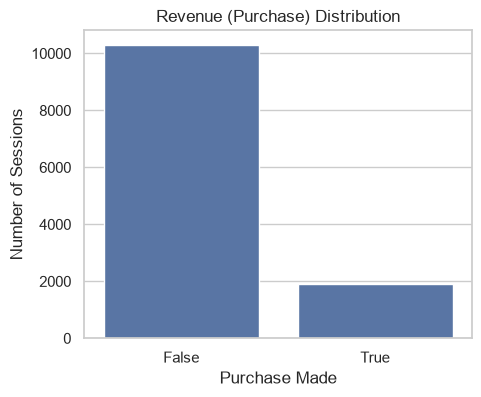

In [7]:
counts = df["Revenue"].value_counts()
pct = df["Revenue"].value_counts(normalize=True) * 100
print(counts)
print(pct.round(2))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="Revenue", data=df, ax=ax)
ax.set_title("Revenue (Purchase) Distribution")
ax.set_xlabel("Purchase Made")
ax.set_ylabel("Number of Sessions")
plt.show()

## 4. Numeric Feature Distributions

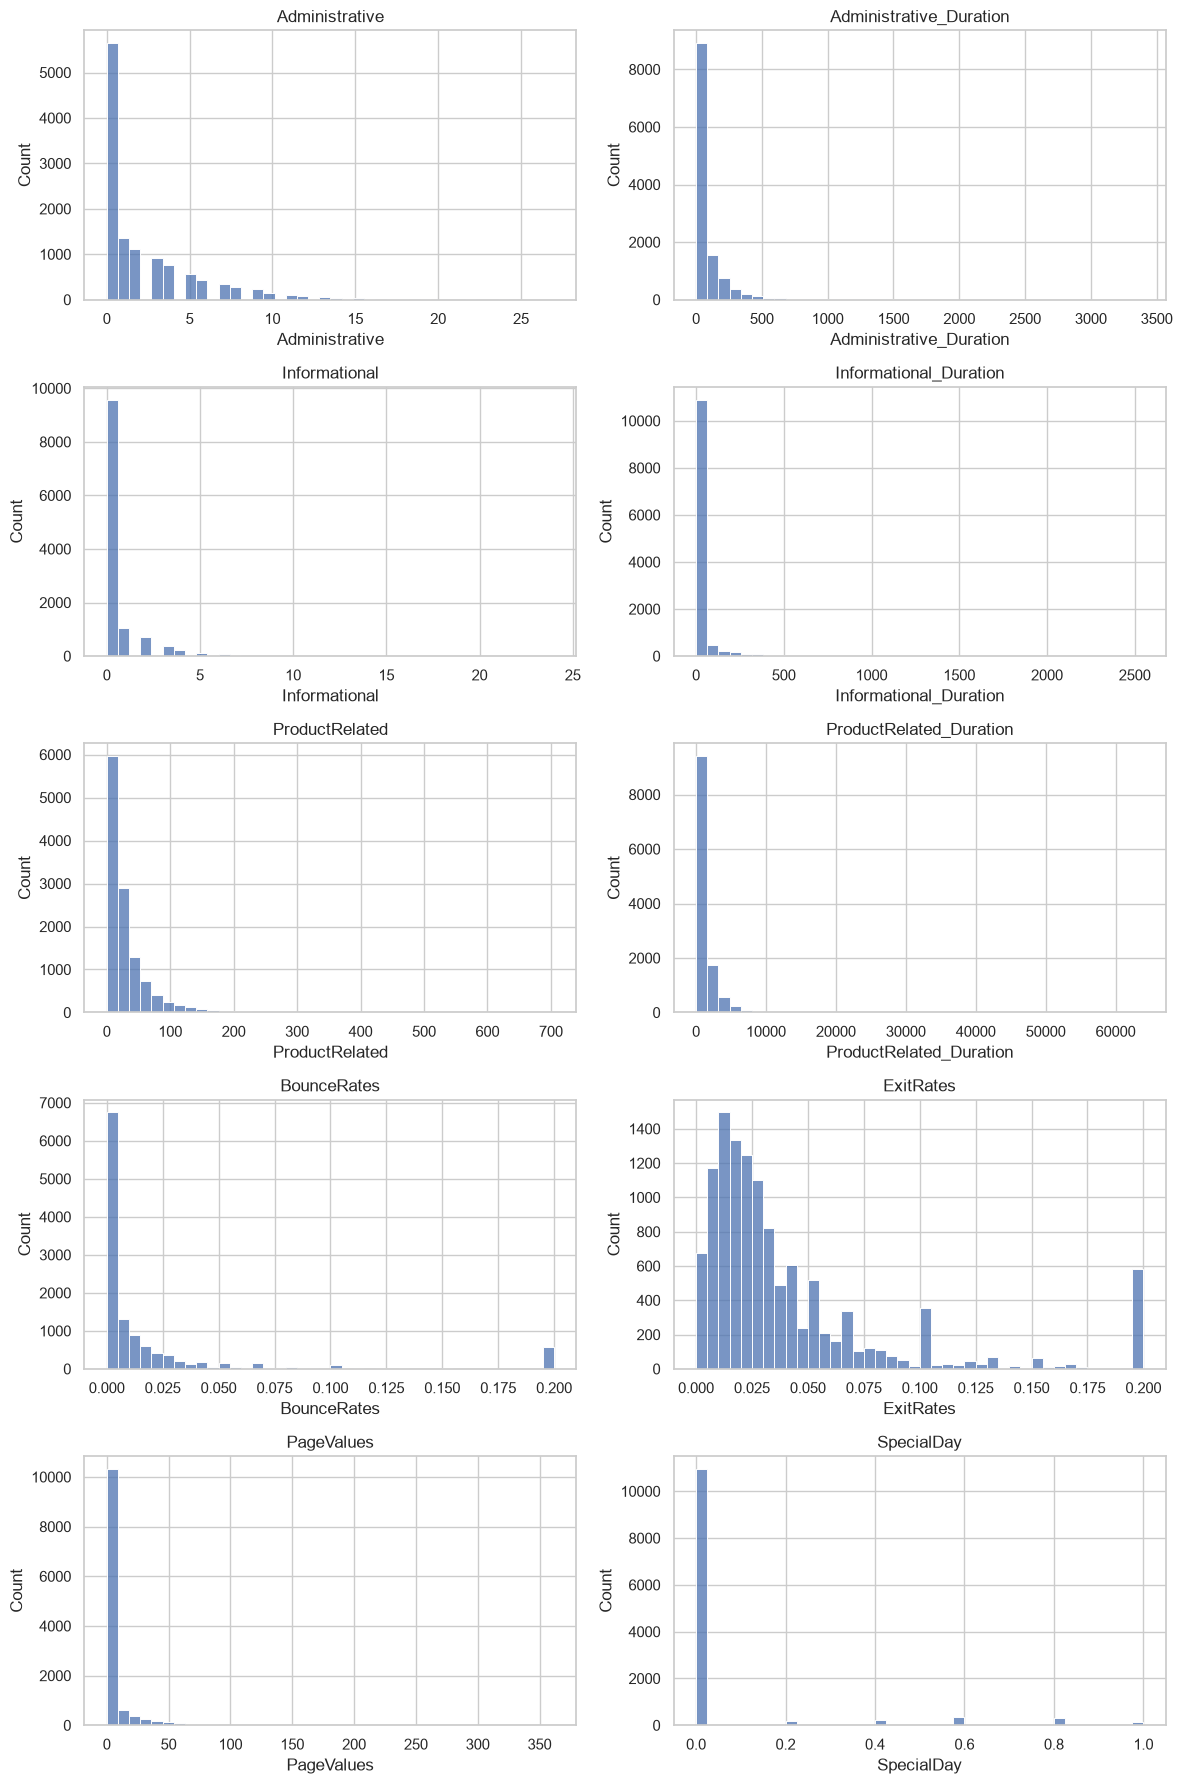

In [8]:
numeric_cols = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]

fig, axes = plt.subplots(5, 2, figsize=(12, 18))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.histplot(df[col], bins=40, ax=ax, kde=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Most duration/count features are heavily right-skewed (many short sessions, a long tail of highly engaged ones) — typical of web analytics data. `PageValues` in particular is expected to be a strong predictor since it directly measures the average value of pages a visitor saw before completing (or abandoning) a transaction.

## 5. Numeric Features vs. Revenue

Boxplots comparing each numeric feature between purchasers and non-purchasers — this directly supports Research Question 1 ("Which browsing behaviour features are associated with online purchase intentions?").

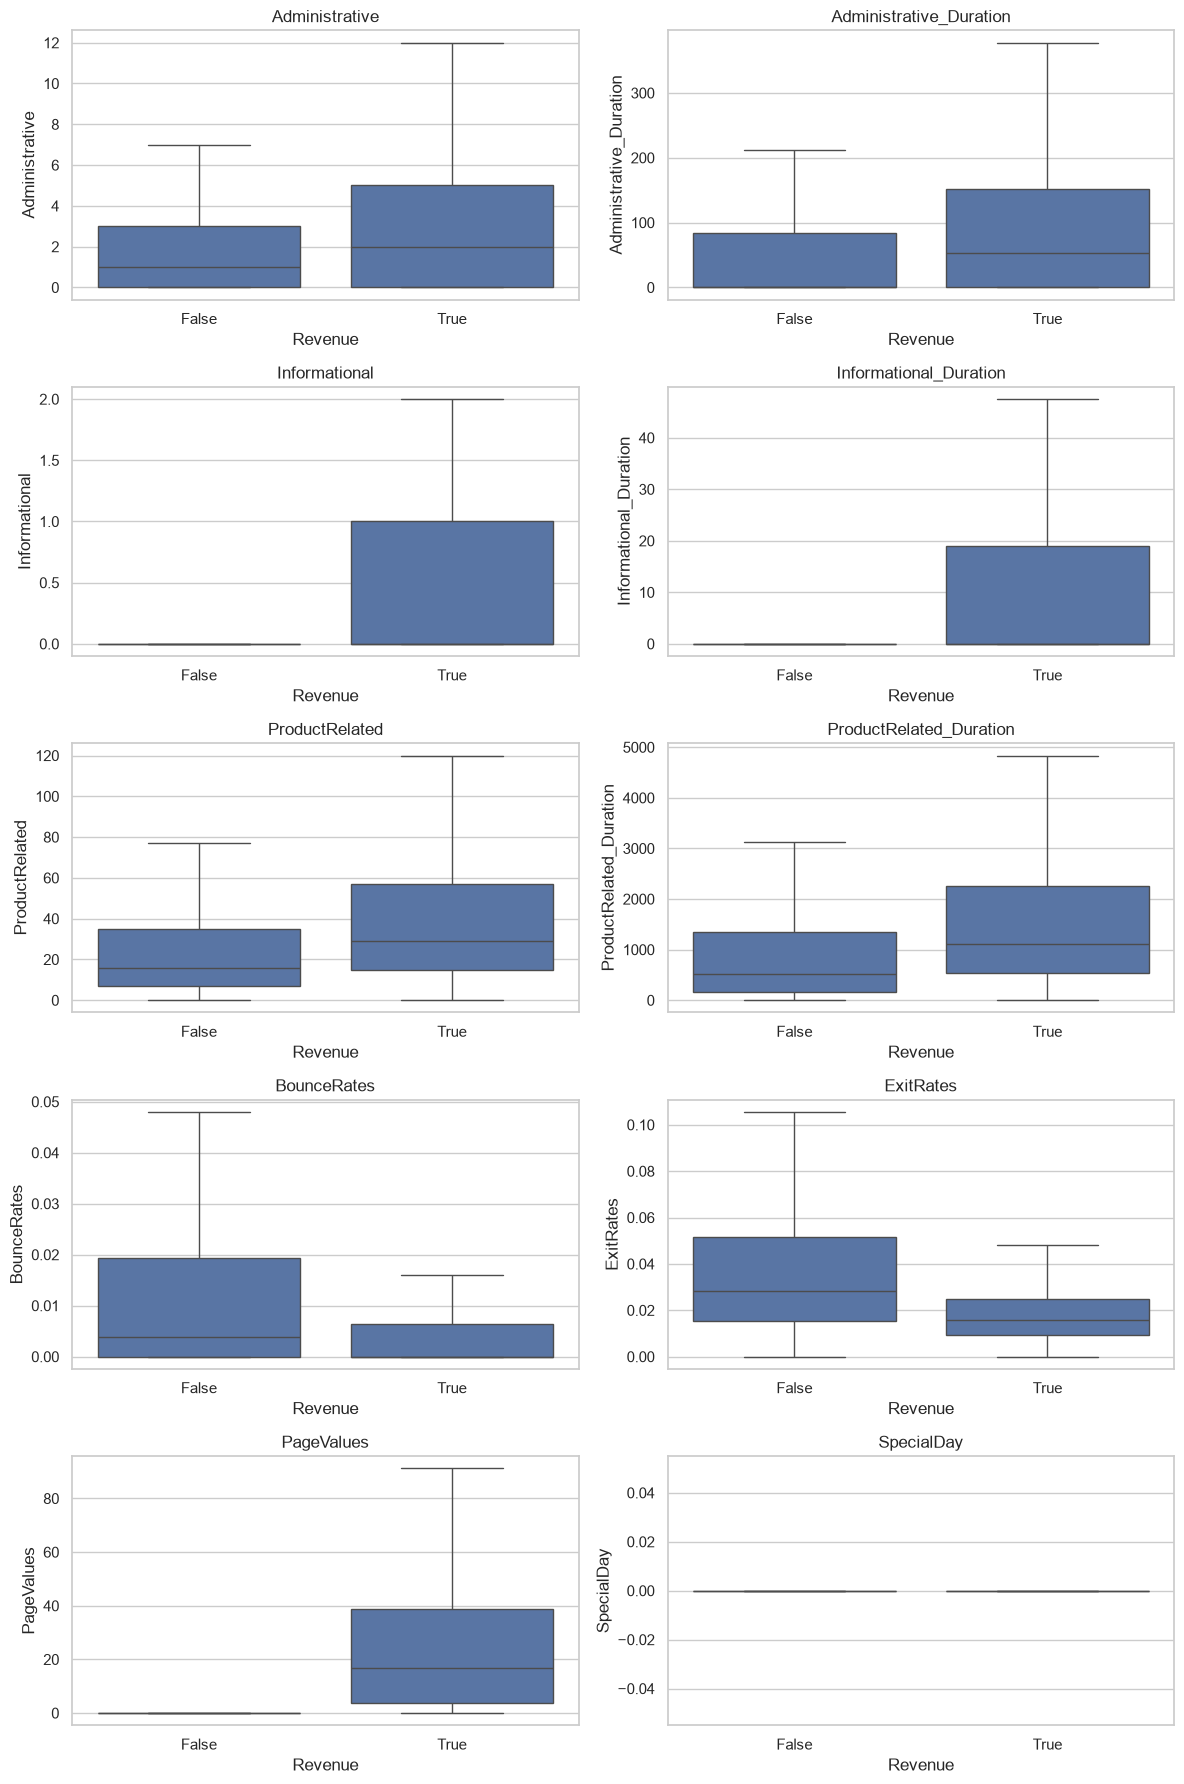

In [9]:
fig, axes = plt.subplots(5, 2, figsize=(12, 18))
for ax, col in zip(axes.ravel(), numeric_cols):
    sns.boxplot(x="Revenue", y=col, data=df, ax=ax, showfliers=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 6. Categorical Features vs. Revenue

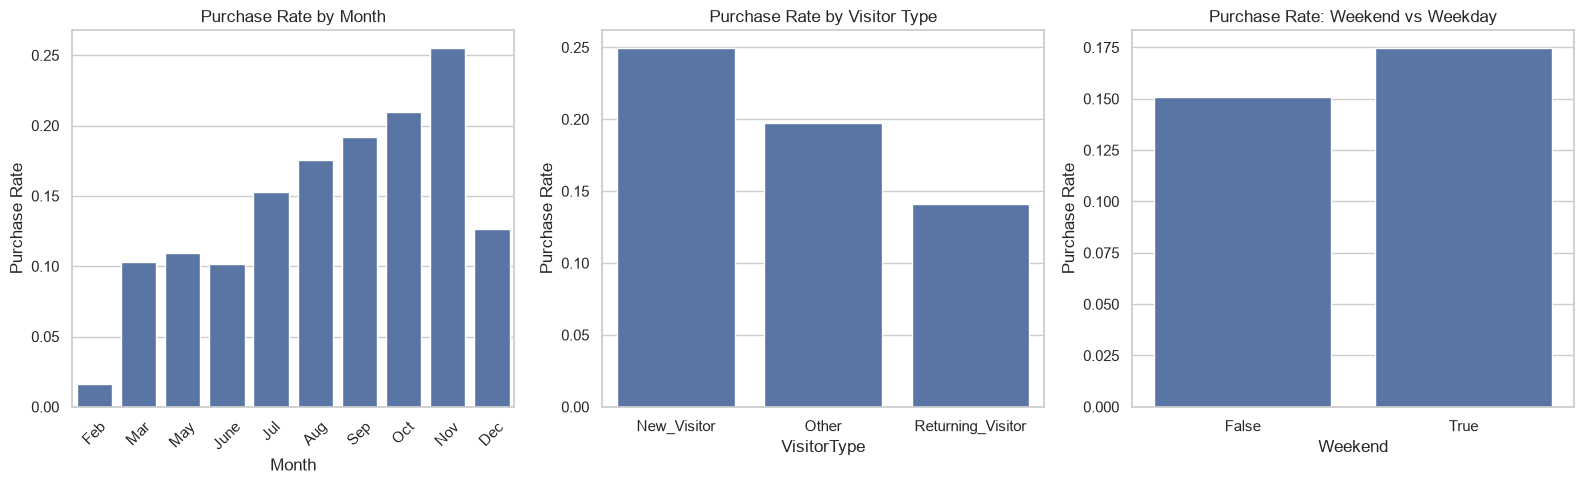

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(x="Month", y="Revenue", data=df, ax=axes[0], errorbar=None,
            order=["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
axes[0].set_title("Purchase Rate by Month")
axes[0].set_ylabel("Purchase Rate")
axes[0].tick_params(axis="x", rotation=45)

sns.barplot(x="VisitorType", y="Revenue", data=df, ax=axes[1], errorbar=None)
axes[1].set_title("Purchase Rate by Visitor Type")
axes[1].set_ylabel("Purchase Rate")

sns.barplot(x="Weekend", y="Revenue", data=df, ax=axes[2], errorbar=None)
axes[2].set_title("Purchase Rate: Weekend vs Weekday")
axes[2].set_ylabel("Purchase Rate")

plt.tight_layout()
plt.show()

## 7. Correlation Heatmap (Numeric Features)

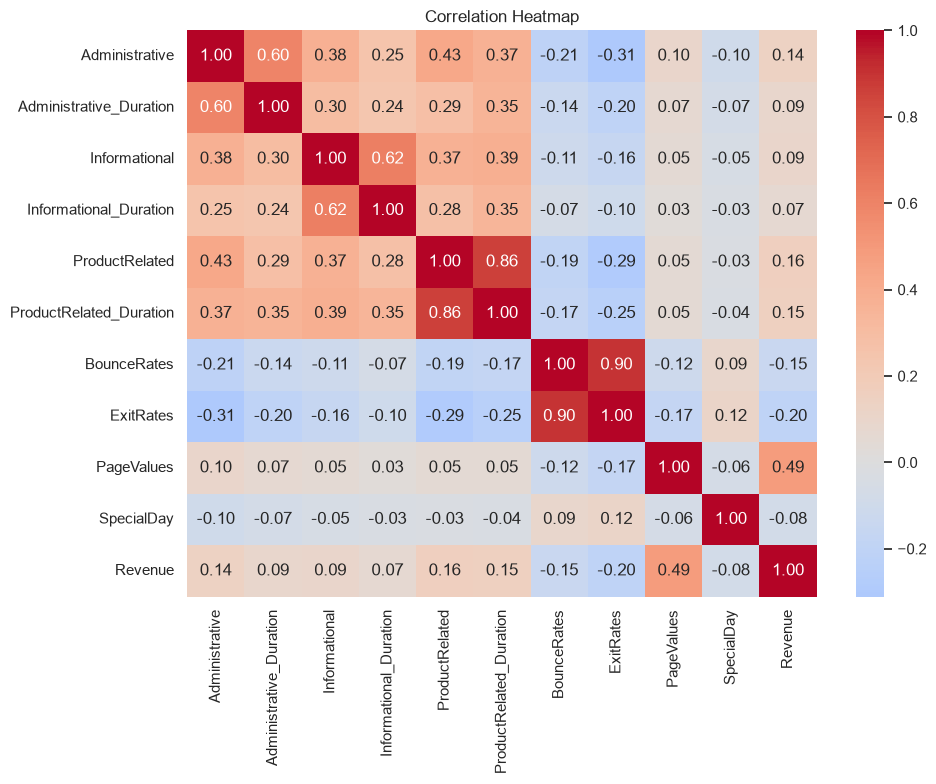

In [11]:
corr_cols = numeric_cols + ["Revenue"]
corr = df[corr_cols].assign(Revenue=df["Revenue"].astype(int)).corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Note `BounceRates` and `ExitRates` are strongly correlated with each other — worth mentioning as a limitation / multicollinearity note for the Logistic Regression model in the Results & Discussion section.

## 8. Save Cleaned Dataset

In [12]:
df.to_csv(cleaned_path, index=False)
print("Saved cleaned dataset to:", cleaned_path)
print("Final shape:", df.shape)

Saved cleaned dataset to: C:\Users\khais\OneDrive - Sunway Education Group\SWA Final Assessment\SWA2124-Final-Assignment-Online-Shoppers-Project\dataset\online_shoppers_intention_cleaned.csv
Final shape: (12205, 18)
